In [60]:
import sys 
from pathlib import Path
current_dir = Path.cwd()

if current_dir.name == 'tasks':
    project_root = current_dir.parent
else:
    project_root = current_dir

sys.path.append(str(project_root))

import pandas as pd
import matplotlib.pyplot as plt
import utils.printer as pr

<h1>Data Understanding and Preprocessing</h1>

In [61]:
df = pd.read_csv('../data/titanic/train.csv')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.expand_frame_repr', False)


pr.print_header(" Data Understanding ", 100)
print(pr.YELLOW, "DATA FRAME HEAD \n", pr.RESET)
display(df.head())
print(pr.YELLOW, "DATA FRAME SHAPE \n", pr.RESET, f"Rows: {df.shape[0]} \n  Cols: {df.shape[1]}",)
print(pr.YELLOW, "DATA FRAME INFO \n", pr.RESET)
df.info() #Return: None
print(pr.YELLOW, "DATA FRAME BASIC STATISTICS \n", pr.RESET, df.describe())

pr.print_header("", 100)
pr.print_header(" Missing Values ", 100)
print(df.isnull().sum())
pr.print_header(" Numerical Features ", 100)
print(df.select_dtypes(include=['number']).columns.to_list())
pr.print_header(" Duplicates ", 100)
print(df.duplicated().sum())
pr.print_header(" Categorical Features ", 100)
print(df.select_dtypes(include=['object', 'category', 'str']).columns.to_list())


  ======================================== Data Understanding ======================================== 
 DATA FRAME HEAD 
 


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


 DATA FRAME SHAPE 
  Rows: 891 
  Cols: 12
 DATA FRAME INFO 
 
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
 DATA FRAME BASIC STATISTICS 
         PassengerId    Survived      Pclass         Age       SibSp       Parch        Fare
count   891.000000  891.000000  891.000000  714.000000  891.000000  891.0

Pclass classified as Numerical Column; But by calculating the unique values and uniqeness ratio we will determine that is an Oridnal Categorical Data

Survived classified as Numerical Column; But by calculating the unique values and uniqeness ratio we will determine that is an Binary Categorical Data

PassengerId classified as Numerical Column; But is is the Identifier

### Detecte Outliers

In [62]:
numerical_cols = df.select_dtypes(['number']).columns

for col in numerical_cols:
      Q1 = df[col].quantile(.25)
      Q3 = df[col].quantile(.75)
      
      IQR = Q3-Q1
      
      lower_bound = Q1 - 1.5 * IQR
      upper_bound = Q3 + 1.5 * IQR
      
      outliers = df[
            (df[col] < lower_bound) |
            (df[col] > upper_bound)
      ]
      
      print(f"\nColumn: {col}")
      print(f"Lower Bound: {lower_bound}")
      print(f"Upper Bound: {upper_bound}")
      if(len(outliers)>0):
            print(pr.RED,f"Outliers Count: {len(outliers)}",pr.RESET)
            continue
      print(f"Outliers Count: {len(outliers)}")


Column: PassengerId
Lower Bound: -444.0
Upper Bound: 1336.0
Outliers Count: 0

Column: Survived
Lower Bound: -1.5
Upper Bound: 2.5
Outliers Count: 0

Column: Pclass
Lower Bound: 0.5
Upper Bound: 4.5
Outliers Count: 0

Column: Age
Lower Bound: -6.6875
Upper Bound: 64.8125
 Outliers Count: 11 

Column: SibSp
Lower Bound: -1.5
Upper Bound: 2.5
 Outliers Count: 46 

Column: Parch
Lower Bound: 0.0
Upper Bound: 0.0
 Outliers Count: 213 

Column: Fare
Lower Bound: -26.724
Upper Bound: 65.6344
 Outliers Count: 116 


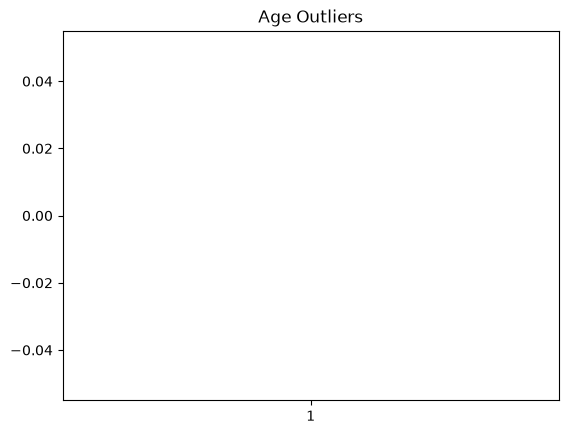

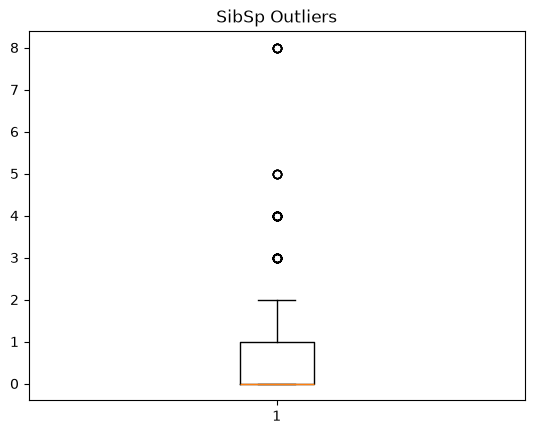

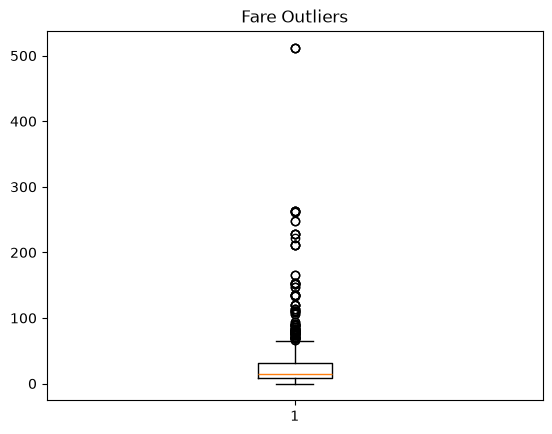

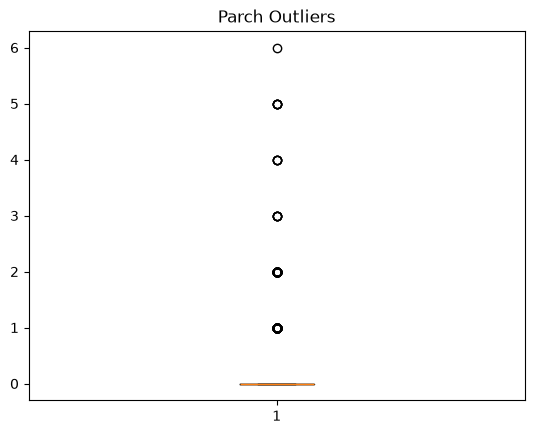

In [63]:

plt.boxplot(data=df, x="Age")
plt.title("Age Outliers")
plt.show()
plt.boxplot(data=df, x="SibSp")
plt.title("SibSp Outliers")
plt.show()
plt.boxplot(data=df, x="Fare")
plt.title("Fare Outliers")
plt.show()
plt.boxplot(data=df, x="Parch")
plt.title("Parch Outliers")
plt.show()

Using IQR we found that there are 4 columns contains outliers (Age, SibSp, Parch, Fare) but by looking at Lower and upper bound values we can notice that:

Age: lower 2.5 yeare, upper 54.5 year which means any value lower than 2.5 or bigger than 54.5 will classified as oulier; but in fact it may be a normal value; values like 1,2, 55, 60, 70 ,75 mathimaticaly classfied as Outliers But those are normal values; 

so we need to take another look

In [64]:
Age_frequency = df["Age"].value_counts().sort_index()
Age_max = df['Age'].min()
Age_min = df['Age'].max()

print(Age_max, Age_min)

#! Now, we can see that Age hasn't Outliers where maximum age is 80 year, minimum age is .42 age and both is normal values
#* Therefore, we can conclude that the IQR or outlier-detection method in general, serve merely as an indecator signaling that we should re-examine the field

0.42 80.0


In [65]:
SibSp_frequency = df["SibSp"].value_counts().sort_index()
SibSp_max = df['SibSp'].min()
SibSp_min = df['SibSp'].max()

print(SibSp_max, SibSp_min)

0 8


In [66]:
Fare_frequency = df["Fare"].value_counts().sort_index()
Fare_max = df['Fare'].min()
Fare_min = df['Fare'].max()

print(Fare_max, Fare_min)

0.0 512.3292


In [67]:
Parch_frequency = df["Parch"].value_counts().sort_index()
Parch_max = df['Parch'].min()
Parch_min = df['Parch'].max()

print(Parch_max, Parch_min)

0 6


After re-examining the date we can found that data we can confirm that there are no Outliers

### Fix - Nulls

Age: Numerical Field (we can replace nulls with mean, median) -> we will use median 
Embarked: Categorical Field so we will replace nulls with mode
Cabin: 77.10% of this column are missing values, mean, mode, median solutions will not work efficiently here, so we will use more efficient way to solve this issue by creating new col [has_cabin] if there is a cabin number we will add 1 if not has_cabin will equal zero.

In [68]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Has_Cabin'] = df['Cabin'].notna().astype(int)


Cabin: After implementing the previous solution, i realized that we had merely transformed the data into a different format - one that no longer causes issues during processing but a significant problem remains: the data, to a large extent, does not reflect reality.

Therefor, I will use another idea to solve this issue i will store the propability of has cabin based on the class e.g 80% of class A has a cabin so Has_Cabin value will be 0.8 for all passengers in class A

P(Has_Cabin | Pclass) = num of cabins for a class / num of passengers for the same class

In [69]:
cabin_p = (df.groupby('Pclass')['Cabin'].apply(lambda x:x.notna().mean()))

df['Has_Cabin'] = df['Cabin'].notna().astype(float)

missing = df['Cabin'].isna()

df.loc[missing, 'Has_Cabin'] = (df.loc[missing, 'Pclass'].map(cabin_p))


### Encoding

In [ ]:
df['Sex'] = df['Sex'].map({'male':0, 'female':1}) #Binary Encoding

df_clean = pd.get_dummies(
      df,
      columns=['Embarked'],
      dtype= int,
      drop_first= False
) #One-Hot Encoding

display(df_clean.head())


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Has_Cabin,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,NaN,0.02444,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,C85,1.00000,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,NaN,0.02444,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,C123,1.00000,0,0,1
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,NaN,0.02444,0,0,1


### Feature Selection

In [71]:
X_df = df_clean.drop(columns=['Survived', 'PassengerId', 'Name', 'Ticket', 'Cabin', 'Has_Cabin'])
Y_df = df['Survived']

display(X_df.head())

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,38.0,1,0,71.2833,1,0,0
2,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,3,0,35.0,0,0,8.0500,0,0,1


## Train/Test Split and Scaling

In [72]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
      X_df,
      Y_df,
      test_size= 0.2,
      train_size= 0.8,
      random_state= 42,
      stratify= Y_df
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\ny_train:", Y_train.shape)
print("y_test:", Y_test.shape)

print(pr.GREEN,"\nOriginal distribution:", pr.RESET)
print(Y_df.value_counts(normalize=True))

print(pr.GREEN,"\nTraining distribution:", pr.RESET)
print(Y_train.value_counts(normalize=True))

print(pr.GREEN,"\nTesting distribution:", pr.RESET)
print(Y_test.value_counts(normalize=True))

X_train: (712, 9)
X_test: (179, 9)

y_train: (712,)
y_test: (179,)
 
Original distribution: 
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64
 
Training distribution: 
Survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64
 
Testing distribution: 
Survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [ ]:
from sklearn.preprocessing import StandardScaler

numerical_features = [
    'Age',
    'Fare',
    'SibSp',
    'Parch'
]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_train_scaled[numerical_features] = scaler.fit_transform(X_train[numerical_features])

X_test_scaled = X_test.copy()
X_test_scaled[numerical_features] = scaler.transform(X_test[numerical_features])


#### why scaling is important for KNN but usually not required for Decision Tree and Random Forest?
* KNN:
      <br>- Reliance on distance measurement.
      <br>- Preventing numerical dominance: Without scaling, variables with larger numerical ranges dominate the distance equation, effectively negating the influence of variables with smaller ranges.

* DT, Random Forest: 
      <br>- Threshold-Based Splitting
     <br>- Monotonic Invariance

### K-Nearest Neighbors (KNN)

k:3	 0.7991825076332117
k:5	 0.8063035555993302
k:7	 0.8048360090613611
k:9	 0.8076529104698118
k:11	 0.8174923667881414
k:13	 0.8174726681768936
k:15	 0.8076233625529401
k:17	 0.8160642174726682
k:19	 0.8160642174726682


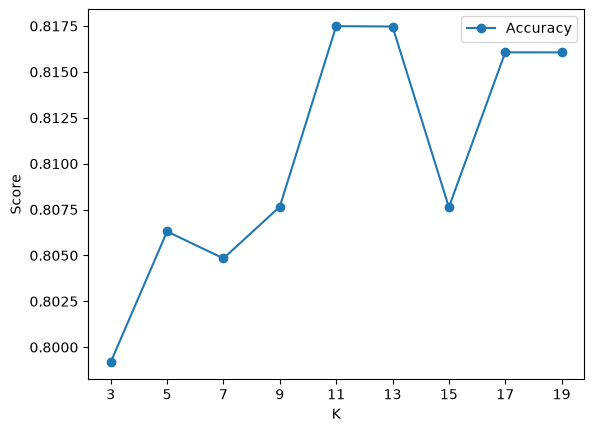

In [121]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate

k_values =  [3,5,7,9,11,13,15,17,19]
accuracies =[]
for k in k_values:
      classifier = KNeighborsClassifier(n_neighbors=k)

      scores = cross_validate(
            classifier,
            X_train_scaled,
            Y_train,
            cv=5,
            scoring=['f1','accuracy']
      )
      
      accuracies.append(scores)
      print(f"k:{k}\t",scores['test_accuracy'].mean())
      
f1_scores_ = [score['test_f1'].mean() for score in accuracies]
accuracies_scores = [accuracy['test_accuracy'].mean() for accuracy in accuracies]

# plt.plot(k_values, f1_scores_, marker='o', label='F1 Score')
plt.plot(k_values, accuracies_scores, marker='o', label='Accuracy')
plt.xlabel('K')
plt.ylabel('Score')
plt.legend()
plt.xticks(k_values)
plt.show()

In [123]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

knn_classifier = KNeighborsClassifier(n_neighbors=11)

knn_classifier.fit(X_train_scaled, Y_train)

Y_prep = knn_classifier.predict(X_test_scaled)

print("Accuracy: ",accuracy_score(Y_test, Y_prep))
print("Precision: ",precision_score(Y_test, Y_prep))
print("Recall: ",recall_score(Y_test, Y_prep))
print("F1-score: ",f1_score(Y_test, Y_prep))
print("Confusion Matrix:")
print(confusion_matrix(Y_test, Y_prep))

Accuracy:  0.7821229050279329
Precision:  0.734375
Recall:  0.6811594202898551
F1-score:  0.706766917293233
Confusion Matrix:
[[93 17]
 [22 47]]


#### Decision Tree

In [76]:
from sklearn.tree import DecisionTreeClassifier

depths = [None, 3, 5, 7, 9, 10, 50, 100]

results = []

for depth in depths:
    dt = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    dt.fit(X_train, Y_train)

    train_pred = dt.predict(X_train)
    test_pred = dt.predict(X_test)

    results.append({
        'max_depth': depth,
        'Train Accuracy': accuracy_score(Y_train, train_pred),
        'Test Accuracy': accuracy_score(Y_test, test_pred)
    })

results_df = pd.DataFrame(results)

display(results_df)

,max_depth,Train Accuracy,Test Accuracy
0,NaN,0.981742,0.821229
1,3.0,0.832865,0.793296
2,5.0,0.865169,0.776536
3,7.0,0.891854,0.793296
4,9.0,0.928371,0.815642
5,10.0,0.938202,0.804469
6,50.0,0.981742,0.821229
7,100.0,0.981742,0.821229


Best Depth: {'max_depth': 5}
Best CV Accuracy: 0.8174825174825175


,param_max_depth,mean_train_score,mean_test_score,std_test_score,rank_test_score
1,5,0.864120,0.817483,0.022925,1
2,7,0.900639,0.816104,0.030629,2
3,9,0.932239,0.811898,0.035656,3
4,10,0.944882,0.809150,0.051038,4
0,3,0.834626,0.809071,0.031886,5
5,50,0.984201,0.785216,0.033860,6
6,100,0.984201,0.785216,0.033860,6
7,None,0.984201,0.785216,0.033860,6


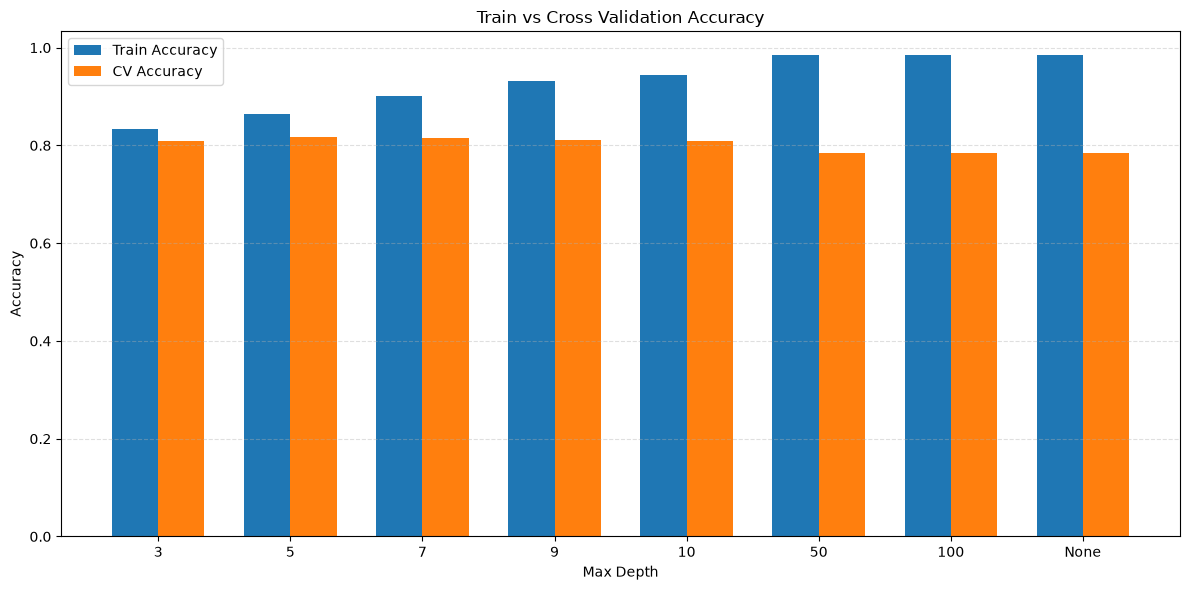

In [91]:
from sklearn.model_selection import GridSearchCV
import numpy as np

dt = DecisionTreeClassifier(random_state=42)

param_grid = {
    'max_depth': [3, 5, 7, 9, 10, 50, 100, None]
}

grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    return_train_score=True
)

grid_search.fit(X_train, Y_train)

print("Best Depth:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)
cv_results = pd.DataFrame(grid_search.cv_results_)

display(
    cv_results[
        [
            'param_max_depth',
            'mean_train_score',
            'mean_test_score',
            'std_test_score',
            'rank_test_score'
        ]
    ].sort_values('rank_test_score')
)

depths = ['3', '5', '7', '9', '10', '50', '100', 'None']

train_scores = [0.834626, 0.864120, 0.900639, 0.932239,
                0.944882, 0.984201, 0.984201, 0.984201]

cv_scores = [0.809071, 0.817483, 0.816104, 0.811898,
             0.809150, 0.785216, 0.785216, 0.785216]

x = np.arange(len(depths))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(x - width/2, train_scores, width, label='Train Accuracy')
ax.bar(x + width/2, cv_scores, width, label='CV Accuracy')


ax.set_title('Train vs Cross Validation Accuracy')
ax.set_xlabel('Max Depth')
ax.set_ylabel('Accuracy')
ax.set_xticks(x)
ax.set_xticklabels(depths)

ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [89]:
dt_classifier = DecisionTreeClassifier(max_depth=5, random_state=42)

dt_classifier.fit(X_train, Y_train)

train_pred = dt_classifier.predict(X_train)
test_pred = dt_classifier.predict(X_test)

print("Accuracy: ",accuracy_score(Y_test, test_pred))
print("Precision: ",precision_score(Y_test, test_pred))
print("Recall: ",recall_score(Y_test, test_pred))
print("F1-score: ",f1_score(Y_test, test_pred))
print("Confusion Matrix:")
print(confusion_matrix(Y_test, test_pred))

Accuracy:  0.776536312849162
Precision:  0.7543859649122807
Recall:  0.6231884057971014
F1-score:  0.6825396825396826
Confusion Matrix:
[[96 14]
 [26 43]]


#### Random Forest

In [90]:
from sklearn.ensemble import RandomForestClassifier

rf_classifier = RandomForestClassifier(
      n_estimators= 100,
      random_state= 42
)

rf_classifier.fit(X_train, Y_train)

Y_pred = rf_classifier.predict(X_test)

print("Accuracy:", accuracy_score(Y_test, Y_pred))
print("Precision:", precision_score(Y_test, Y_pred))
print("Recall:", recall_score(Y_test, Y_pred))
print("F1-score:", f1_score(Y_test, Y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(Y_test, Y_pred))

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_classifier.feature_importances_
})

print(feature_importance.head(10))

Accuracy: 0.8212290502793296
Precision: 0.8135593220338984
Recall: 0.6956521739130435
F1-score: 0.75

Confusion Matrix:
[[99 11]
 [21 48]]
      Feature  Importance
0      Pclass    0.095257
1         Sex    0.274639
2         Age    0.243967
3       SibSp    0.047251
4       Parch    0.040431
5        Fare    0.260635
6  Embarked_C    0.011232
7  Embarked_Q    0.008263
8  Embarked_S    0.018325


In [80]:
import time
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "KNN": (
        KNeighborsClassifier(n_neighbors=5),
        X_train_scaled,
        X_test_scaled
    ),
    "Decision Tree": (
        DecisionTreeClassifier(max_depth=9, random_state=42),
        X_train,
        X_test
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=100, random_state=42),
        X_train,
        X_test
    )
}

results = []

for name, (model, x_train, x_test) in models.items():

    training_times = []
    prediction_times = []

    for _ in range(10):
        current_model = clone(model)

        start = time.perf_counter()
        current_model.fit(x_train, Y_train)
        training_times.append(time.perf_counter() - start)

        start = time.perf_counter()
        current_model.predict(x_test)
        prediction_times.append(time.perf_counter() - start)

    results.append({
        "Model": name,
        "Training Time (ms)": sum(training_times) / 10 * 1000,
        "Prediction Time (ms)": sum(prediction_times) / 10 * 1000
    })

time_results = pd.DataFrame(results)
print(time_results)

           Model  Training Time (ms)  Prediction Time (ms)
0            KNN             2.09461               2.90913
1  Decision Tree             2.38306               0.69768
2  Random Forest           134.63718               9.51753


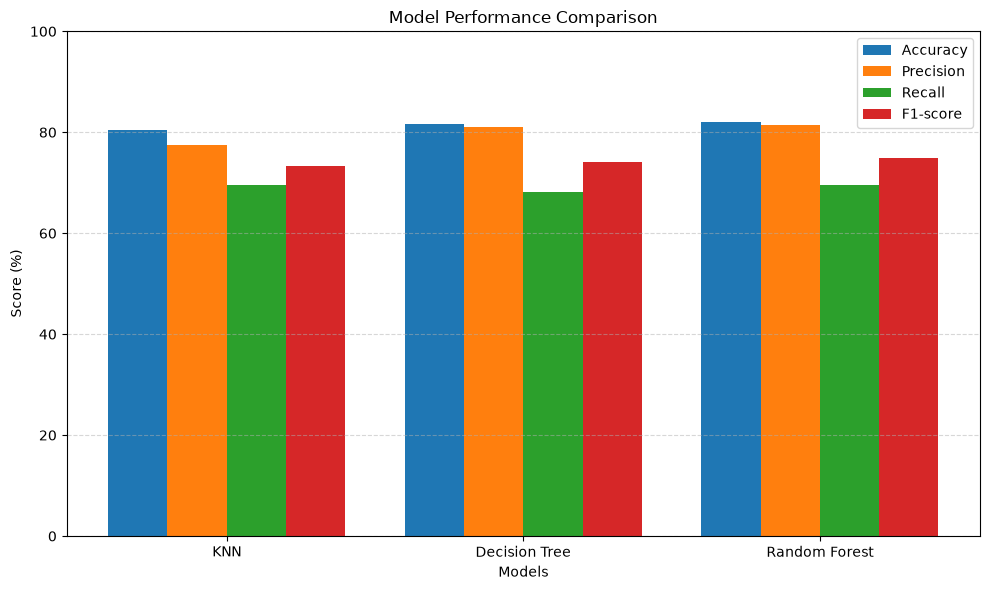

In [81]:
import numpy as np

models = ['KNN', 'Decision Tree', 'Random Forest']

accuracy = [80.45, 81.56, 82.12]
precision = [77.42, 81.03, 81.36]
recall = [69.57, 68.12, 69.57]
f1_score_ = [73.28, 74.02, 75.00]

x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(10, 6))

plt.bar(x - 1.5*width, accuracy, width, label='Accuracy')
plt.bar(x - 0.5*width, precision, width, label='Precision')
plt.bar(x + 0.5*width, recall, width, label='Recall')
plt.bar(x + 1.5*width, f1_score_, width, label='F1-score')

plt.xlabel('Models')
plt.ylabel('Score (%)')
plt.title('Model Performance Comparison')

plt.xticks(x, models)
plt.ylim(0, 100)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

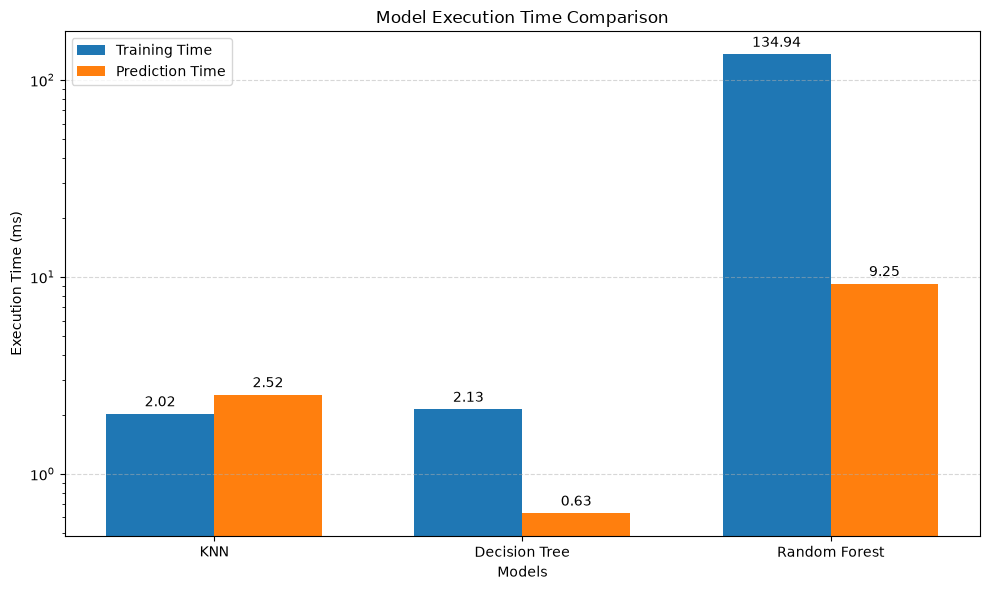

In [82]:
models = ['KNN', 'Decision Tree', 'Random Forest']

training_times = [2.01789, 2.12729, 134.93536]
prediction_times = [2.52238, 0.63154, 9.24530]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

train_bars = plt.bar(
    x - width / 2,
    training_times,
    width,
    label='Training Time'
)

predict_bars = plt.bar(
    x + width / 2,
    prediction_times,
    width,
    label='Prediction Time'
)

plt.xlabel('Models')
plt.ylabel('Execution Time (ms)')
plt.title('Model Execution Time Comparison')

plt.xticks(x, models)
plt.yscale('log')  

plt.bar_label(train_bars, fmt='%.2f', padding=3)
plt.bar_label(predict_bars, fmt='%.2f', padding=3)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

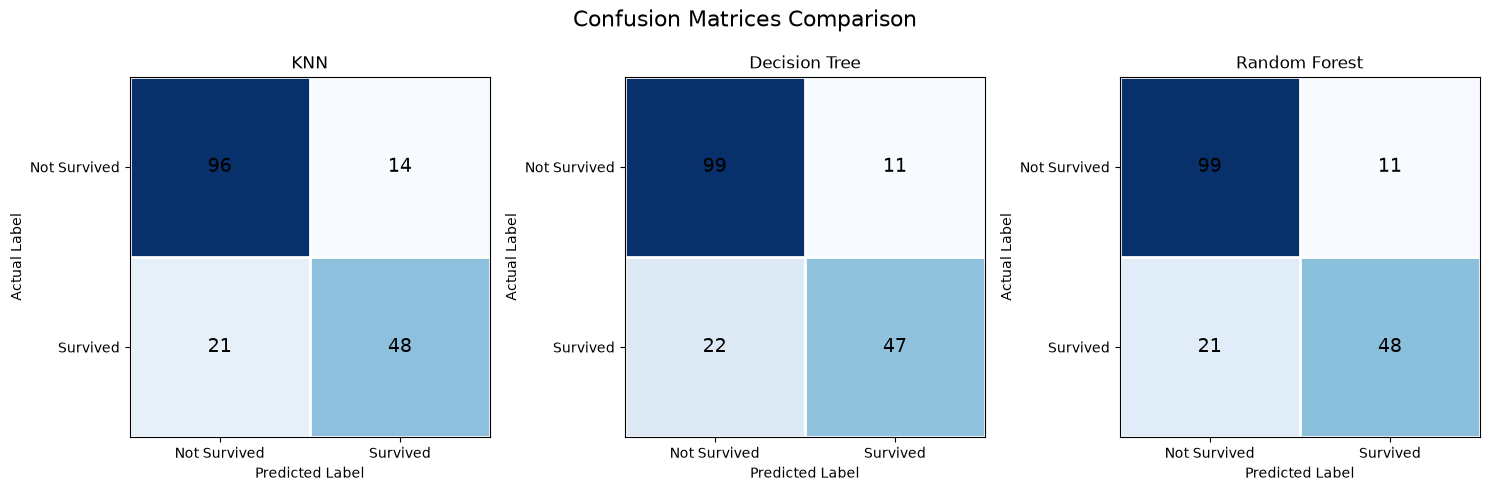

In [83]:
import matplotlib.pyplot as plt
import numpy as np

confusion_matrices = {
    'KNN': np.array([[96, 14], [21, 48]]),
    'Decision Tree': np.array([[99, 11], [22, 47]]),
    'Random Forest': np.array([[99, 11], [21, 48]])
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (model_name, cm) in zip(axes, confusion_matrices.items()):

    ax.imshow(cm, cmap='Blues')

    ax.set_title(model_name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(['Not Survived', 'Survived'])
    ax.set_yticklabels(['Not Survived', 'Survived'])

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, cm[i, j],
                ha='center',
                va='center',
                color='black',
                fontsize=14
            )

    ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    ax.grid(which='minor', color='white', linestyle='-', linewidth=2)
    ax.tick_params(which='minor', bottom=False, left=False)

fig.suptitle('Confusion Matrices Comparison', fontsize=16)

plt.tight_layout()
plt.show()

<p style="font-size:18px">Although Random Forest achieved the highest F1-score (75%), its improvement over Decision Tree (74.02%) was relatively small. However, Random Forest required approximately 63 times more training time and 14.6 times more prediction time. Therefore, <strong style="color:red; font-size:22px">Decision Tree was selected as the most efficient model</strong>, providing comparable predictive performance with significantly lower computational cost</p>